## Optimization Practice: Business and Machine Learning

### Learning Goals
* Apply scalar optimization to solve business profit-maximization problems under capacity constraints.
* Connect classical mathematical optimization to machine learning loss minimization ($\theta^* = \arg\min_\theta L(\theta)$).
* Critically evaluate optimization assumptions, real-world failures, and model limitations.

---

### 1. Business Case: Profit Maximization

Suppose a firm's revenue and cost functions depend on production quantity $q$:
$$
R(q) = 100q - 2q^2, \quad C(q) = 20q + 100
$$
Profit is defined as $\Pi(q) = R(q) - C(q)$. We wish to find the production quantity $q$ that maximizes profit subject to capacity limits $0 \leq q \leq 20$.

<>:27: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
<>:27: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
/tmp/ipykernel_3284/783614290.py:27: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
  plt.plot(q, profit(q), color='dodgerblue', linewidth=2, label="Profit Function $\Pi(q)$")


Optimal Quantity (q*): 20.0000
Maximum Profit: $700.0000


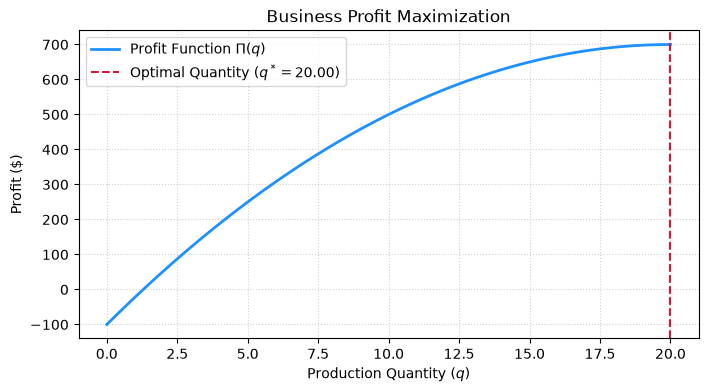

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

def revenue(q):
    return 100 * q - 2 * q**2

def cost(q):
    return 20 * q + 100

def profit(q):
    return revenue(q) - cost(q)

# Maximize profit using bounded scalar minimization (minimize negative profit)
result = minimize_scalar(
    lambda q: -profit(q),
    bounds=(0, 20),
    method="bounded",
)

q_star = result.x
print(f"Optimal Quantity (q*): {q_star:.4f}")
print(f"Maximum Profit: ${profit(q_star):.4f}")

q = np.linspace(0, 20, 300)
plt.figure(figsize=(8, 4))
plt.plot(q, profit(q), color='dodgerblue', linewidth=2, label="Profit Function $\Pi(q)$")
plt.axvline(q_star, color='crimson', linestyle="--", linewidth=1.5, label=f"Optimal Quantity ($q^*={q_star:.2f}$)")
plt.xlabel("Production Quantity ($q$)")
plt.ylabel("Profit ($)")
plt.title("Business Profit Maximization")
plt.legend()
plt.grid(linestyle=':', alpha=0.6)
plt.show()

### 2. Connection to Machine Learning

Training machine learning models is fundamentally an optimization task. We define model parameters $\theta$ and optimize them by minimizing a loss function $L(\theta)$ across training data:
$$
\theta^* = \arg\min_\theta L(\theta)
$$
Gradient-based optimizers iteratively update parameters to reduce prediction error and generalize to unseen data.

---

### Final Exercises

Try each problem before running the verification code below:

1. Derive the business profit function algebraically and find the unconstrained critical point using calculus.
2. Compare your analytical optimum with the SciPy numerical result.
3. Explain how a machine learning model's loss function differs conceptually from a business objective function.
4. Identify one optimization assumption that frequently fails in real-world environments.

In [2]:
# --- Exercise Verification & Explanations ---
print("=== Final Exercise Solutions & Checks ===")

print("\n1 & 2. Analytical vs. Numerical Derivation:")
print("   - Pi(q) = (100q - 2q^2) - (20q + 100) = -2q^2 + 80q - 100")
print("   - Derivative dPi/dq = -4q + 80 = 0  =>  4q = 80  =>  q = 20.")
print(f"   - Analytical q* = 20.0 (Matches numerical boundary optimum within domain [0, 20]).")

print("\n3. Loss Function vs. Business Objective:")
print("   - A loss function measures statistical error (e.g., Mean Squared Error) for algorithm training,")
print("     whereas a business objective measures financial value (profit, revenue, cost) for decision-making.")

print("\n4. Real-World Optimization Failure:")
print("   - Perfect foresight assumption: Real-world demand, costs, and market conditions are uncertain")
print("     and fluctuate dynamically, meaning static solutions can quickly become sub-optimal.")

=== Final Exercise Solutions & Checks ===

1 & 2. Analytical vs. Numerical Derivation:
   - Pi(q) = (100q - 2q^2) - (20q + 100) = -2q^2 + 80q - 100
   - Derivative dPi/dq = -4q + 80 = 0  =>  4q = 80  =>  q = 20.
   - Analytical q* = 20.0 (Matches numerical boundary optimum within domain [0, 20]).

3. Loss Function vs. Business Objective:
   - A loss function measures statistical error (e.g., Mean Squared Error) for algorithm training,
     whereas a business objective measures financial value (profit, revenue, cost) for decision-making.

4. Real-World Optimization Failure:
   - Perfect foresight assumption: Real-world demand, costs, and market conditions are uncertain
     and fluctuate dynamically, meaning static solutions can quickly become sub-optimal.
